## Preliminaries

Samplewise experiments with **Monte-Carlo Dropout**, **quantile saliency maps** and **Pixel Flipping**.

In [1]:
!pwd
#import os
#os.chdir('C:\\Users\\Teo\\Documents\\Projects') # equivalent to /teo on server

import sys
sys.path.append('./tf-explain/')
sys.path.append('./Quantus/Quantus/')
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import time
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers
from wingbeats import xai as wx

from tf_explain.core.vanilla_gradients import VanillaGradients
from tf_explain.core.gradients_inputs import GradientsInputs
from tf_explain.core.integrated_gradients import IntegratedGradients

No module named 'nltk'


In [3]:
use_mini_dataset   = True
compress_B_lucorum = True
bees_subfolder = '22_species/' if compress_B_lucorum else '25_species/'

dataset_folder = 'Bees_Christian/' if use_mini_dataset else 'Bees/'
metafolder = './beexplainable/metafiles/'

BEES_PATH = '../data/data_lstudio/' + dataset_folder
BEES_MASKS_PATH = '../data/Wildbienen/' + dataset_folder[:-1] + '_masks/Whole/'
IMAGES_PATH = metafolder + dataset_folder + 'images.txt'
MASKS_PATH = metafolder + dataset_folder + 'masks.txt'
IMAGES_LABELS_PATH = metafolder + dataset_folder + bees_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + dataset_folder + bees_subfolder + 'classes.txt'

W_H_PATH = metafolder + dataset_folder + 'widths_heights.txt'
BBOX_PATH = metafolder + dataset_folder + 'bounding_boxes.txt'
PART_CONTOURS = metafolder + dataset_folder + 'part_contours.npy'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/pf_mcd_examples/'

## Load images

In [4]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

In [5]:
batch_size = 64
img_height = img_width = 224
crop_to_bbox = False # whether to crop image to bbox
overlay_mask = False # whether to segment object and hide background

In [6]:
# Add extension to path if extra input transformation is enabled
input_form = 'raw'
if crop_to_bbox and not overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_bbox/'
    input_form = 'bbox'
elif not crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked/Whole/'
    input_form = 'mask'
elif crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked_bbox/'
    input_form = 'mask_bbox'
print(BEES_PATH)

../data/data_lstudio/Bees_Christian/


In [7]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image_and_mask(file_id, img_lookup, img_width, img_height,
                                                                  BEES_PATH, BEES_MASKS_PATH),
                                          label)

2024-04-11 16:42:25.720844: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-11 16:42:26.193935: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [8]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images (first item in the tuples, second is the mask)
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: ((normalization_layer(x[0]), x[1]), y))

In [9]:
for image_mask_batch, labels_batch in test_set.take(1):
    print(image_mask_batch[0].shape)
    print(image_mask_batch[1].shape)
    print(labels_batch[0])

(64, 224, 224, 3)
(64, 224, 224, 1)
tf.Tensor(0, shape=(), dtype=uint8)


2024-04-11 16:42:28.333933: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


2024-04-11 16:42:29.511571: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


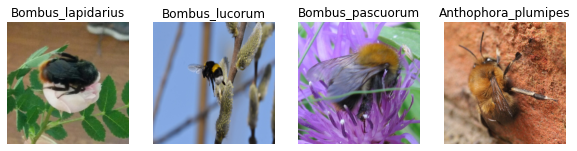

In [10]:
plt.figure(figsize = (10, 10))
num_cols = min(4, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[0][i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

## XAI

In [11]:
# Define model parameters
in_shape = (img_width, img_height, 3)
drop_rate, lr, reg = 0.5, 1e-4, 1e-4

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
dataset_type = 'all' # model was trained on whole dataset and is now tested on mini dataset
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_raw' # model was trained on raw whole dataset
weights_file = MODELS_PATH + dataset_type + '/' + bees_subfolder + model_name + '/' + model_name + '.h5' # path to load weights from
print('Model loaded from ' + weights_file)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

Model loaded from ./beexplainable/models/all/22_species/ResNet50_iNat_raw/ResNet50_iNat_raw.h5


In [12]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

2024-04-11 16:42:32.456213: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-04-11 16:42:32.995203: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-11 16:42:32.996457: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-11 16:42:32.996492: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-04-11 16:42:32.997649: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-11 16:42:32.997741: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.
2024-04-11 16:42:37.784784: W tensorflow/core/kernels/data/cach

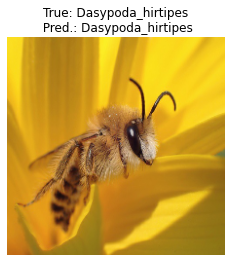

In [13]:
# Pick a correctly predicted image
counts, max_it = 0, 6 # how many hits to find
for img_mask, y_true in test_set.unbatch():
    # Predict class of example
    img, mask = img_mask
    preds = model.predict(np.expand_dims(img, axis = 0))
    if preds[0][y_true] < 0.7: # pick a hard example i.e. < 0.7 or easy example > 0.8
        y_pred = np.argmax(preds)

        if y_pred == y_true:
            counts += 1
            if counts == max_it: break

plt.imshow(img)
plt.title('True: ' + classes[y_true] + '\n Pred.: ' + classes[y_pred])
plt.axis('off')
plt.show()

### MC-Dropout

#### Distribution of predictions

In [14]:
# Predictions without MCD
model.layers[1].mcdrop = False
model(tf.expand_dims(img, axis=0))

<tf.Tensor: shape=(1, 22), dtype=float32, numpy=
array([[1.05536905e-07, 3.09474721e-08, 3.54178774e-05, 7.10216364e-06,
        1.63133140e-03, 2.72147238e-01, 7.91450638e-09, 1.08890813e-02,
        3.23606997e-07, 1.40724405e-05, 1.21945050e-06, 1.19819124e-05,
        5.90519505e-07, 5.45668045e-05, 6.95620201e-07, 6.74844265e-01,
        1.06254095e-06, 2.37339304e-06, 2.94667389e-02, 1.08914860e-02,
        2.24854418e-07, 4.71207251e-08]], dtype=float32)>

In [15]:
# Predictions with MCD
model.layers[1].mcdrop = True

preds, num_infer = [], 500
nbins = num_infer//10 # histogram bins (for monte carlso predictions and quantile maps)
for _ in range(num_infer):
    pred = model(tf.expand_dims(img, axis=0), training=False)
    preds.append(pred[0])

print(f"Mean: {np.mean(preds, axis=0)}")
print(f"Median: {np.median(preds, axis=0)}")
print(f"STd. Dev.: {np.std(preds, axis=0)}")

Mean: [2.6526985e-07 9.1449984e-08 7.2422343e-05 1.3461584e-05 3.1150030e-03
 2.9561555e-01 2.5623034e-08 1.5298628e-02 6.4576892e-07 2.6761010e-05
 2.7310373e-06 2.3458892e-05 1.4527003e-06 1.1476792e-04 1.5828314e-06
 6.1711997e-01 2.6261118e-06 4.5748425e-06 4.4860497e-02 2.3724902e-02
 4.9462227e-07 1.5635075e-07]
Median: [8.5483720e-08 2.4455773e-08 3.0530722e-05 5.8359478e-06 1.2777904e-03
 2.5519079e-01 6.9536239e-09 9.0067927e-03 2.7374955e-07 1.3182485e-05
 9.4814141e-07 9.7621887e-06 4.6029754e-07 4.3055072e-05 6.2065340e-07
 6.4500284e-01 8.2060535e-07 2.0857974e-06 2.3346800e-02 8.8319164e-03
 1.6697172e-07 3.7851031e-08]
STd. Dev.: [1.0087092e-06 3.3771923e-07 1.4914018e-04 2.0530229e-05 5.1509081e-03
 2.1238433e-01 6.6783691e-08 1.9047942e-02 1.4351868e-06 4.9531405e-05
 6.0288162e-06 3.9039602e-05 3.5513199e-06 1.9490620e-04 2.9143234e-06
 2.2869688e-01 6.5742706e-06 9.9432318e-06 5.7657059e-02 4.2956606e-02
 9.7060285e-07 4.2878926e-07]


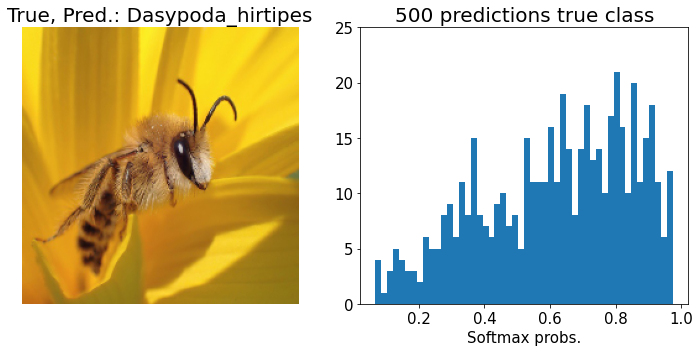

In [16]:
# Plot the example along with the distributions
title_size, ticks_size = 20, 15
fig = plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img)
plt.title('True, Pred.: ' + classes[y_pred], fontsize = title_size)
plt.axis('off')

plt.subplot(122)
plt.hist(np.asarray(preds)[:,y_true], bins=nbins, density = False)
plt.title(str(num_infer) + ' predictions true class', fontsize = title_size)
# for wrongly predicted (high uncertainty)
#plt.xticks(np.linspace(0.0, 1.0, 6), fontsize = ticks_size)
#plt.yticks(np.linspace(5, 20, 4), fontsize = ticks_size)

# for correctly predicted (high certainty)
plt.xticks(fontsize = ticks_size)
plt.xlabel('Softmax probs.', fontsize = ticks_size)
plt.yticks(np.linspace(0, 25, 6), fontsize = ticks_size)

plt.tight_layout()
#fig.savefig(FIGURES_PATH + classes[y_pred] + '_mcd.png', bbox_inches = 'tight')
plt.show()

#### Quantiles

In [17]:
# Compute explanation w.r.t. true or predicted class
explain_true = True # True = explain w.r.t. true label, False = w.r.t. predicted label
model.layers[1].mcdrop = True
q_maps = {} # dictionary of q-maps for every xai-method
explainers = [VanillaGradients(), GradientsInputs(), IntegratedGradients()]
expl_names = ['Gradient', 'Input x Gradient', 'Integrated Gradients']
q = [0.05, 0.25, 0.5, 0.75, 0.95] # quantiles

In [18]:
start_time = time.time()
for e, n in zip(explainers, expl_names):
    mcd_maps = []
    for _ in range(num_infer):
        hm = e.explain((np.array([img]), None), model, y_true.numpy() if explain_true else y_pred, norm = "min_max")
        mcd_maps.append(hm)
    print(f"Computed {num_infer} MCD-maps for {n}.")

    # Compute quantile maps
    q_maps[n] = wx.quantile_maps(mcd_maps, q, nbins)
    print('Quantiles for ' + n + ' done!')

print("--- %s seconds ---" % (time.time() - start_time))

Computed 500 MCD-maps for Gradient.
Quantiles for Gradient done!
Computed 500 MCD-maps for Input x Gradient.
Quantiles for Input x Gradient done!
Computed 500 MCD-maps for Integrated Gradients.
Quantiles for Integrated Gradients done!
--- 127.15154218673706 seconds ---


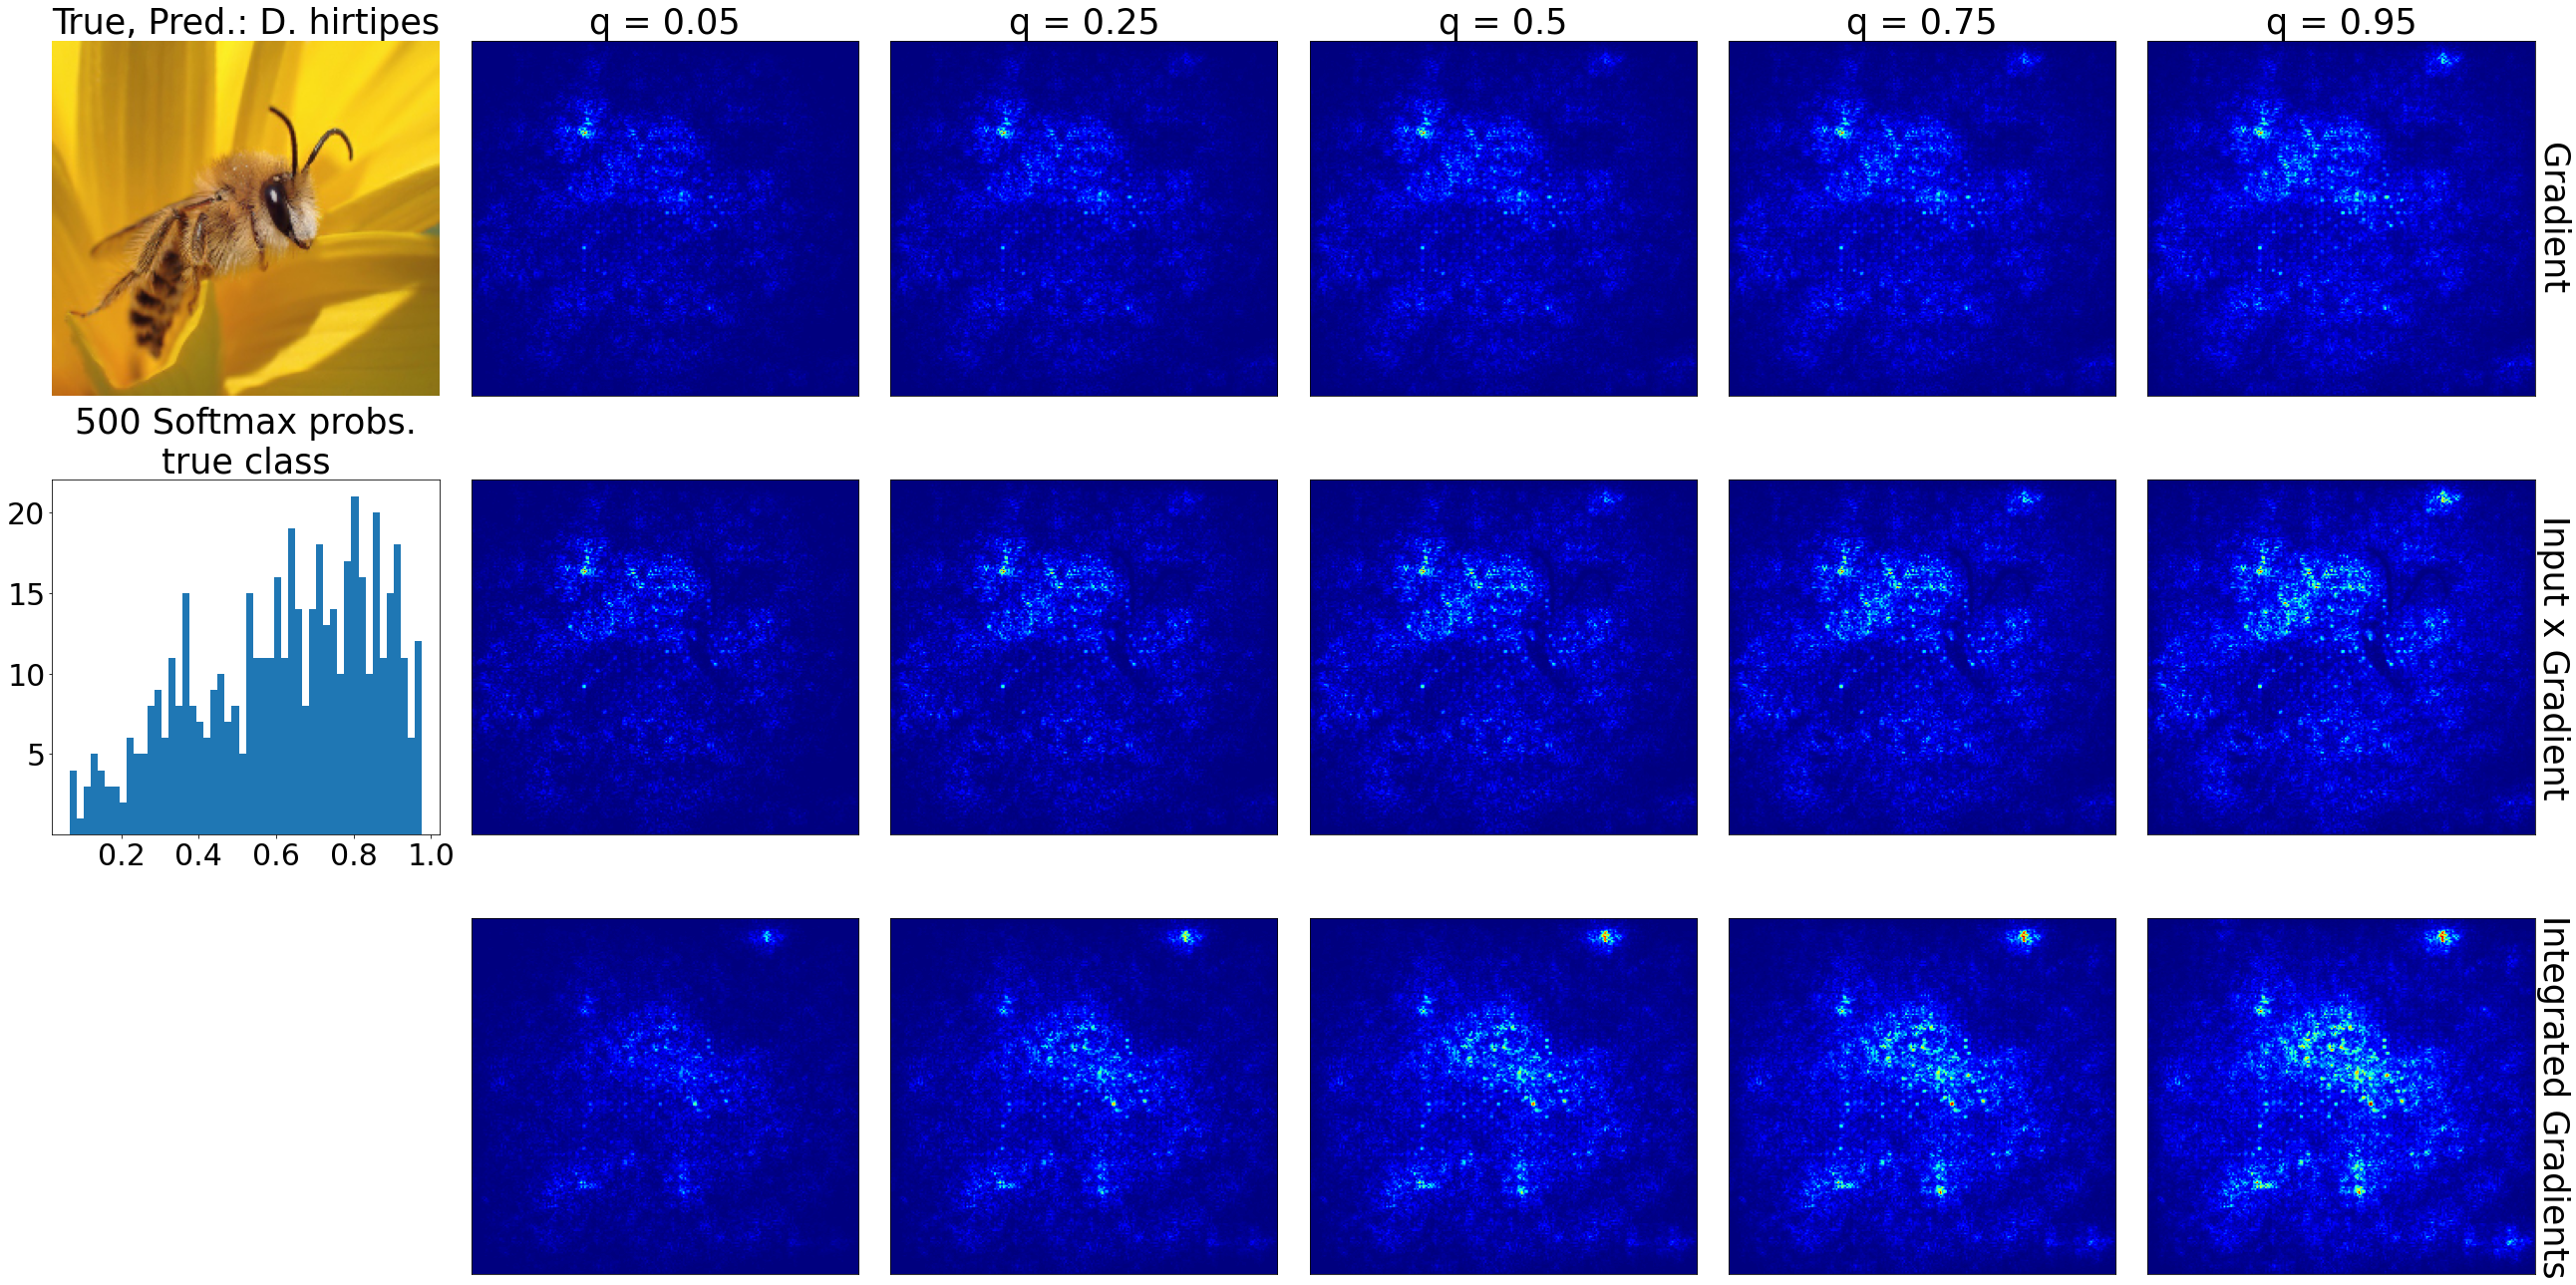

In [19]:
num_cols, num_rows = len(q)+1, len(explainers)
title_size, ticks_size = 35, 35

fig = plt.figure(figsize = (6 * num_cols, 6 * num_rows))

plt.subplot(num_rows, num_cols, 1)
plt.imshow(img, aspect = 'auto')
gen, spec = classes[y_pred].split('_')
title_label = gen[0] + '. ' + spec
plt.title('True, Pred.: ' + title_label, fontsize = title_size)
plt.axis('off')

plt.subplot(num_rows, num_cols, len(q)+2)
plt.hist(np.asarray(preds)[:,y_true], bins=nbins, density = False)
plt.xticks(fontsize = ticks_size-5)
plt.yticks(np.linspace(5, 20, 4), fontsize = ticks_size-5)
plt.title(str(num_infer) + ' Softmax probs.\ntrue class', fontsize = title_size)

for i in range(num_rows):
    for j in range(num_cols-1):
        ax = plt.subplot(num_rows, num_cols, j+i*num_cols+2)
        plt.imshow(q_maps[expl_names[i]][j], cmap='jet',
                   norm = plt.Normalize(np.min(q_maps[expl_names[i]]), np.max(q_maps[expl_names[i]])),
                   # Note: very important to keep the same normalization across all quantile maps, otherwise very tiny values in the first quantiles get
                   #       stretched out in the colormap and give the wrong impression of high heatmap values!
                   aspect='auto')
        if i == 0:
            plt.title('q = ' + str(q[j]), fontsize = title_size)
        plt.xticks([])
        plt.yticks([])
        if j == num_cols-2:
            ax.yaxis.set_label_position("right")
            ax.set_ylabel(expl_names[i], fontsize = ticks_size, rotation = -90, labelpad = 35)

plt.tight_layout()
fig.savefig(FIGURES_PATH + classes[y_pred] + '_qmaps_softmax_distrib.png', bbox_inches = 'tight')
plt.show()

### Pixel Flipping

#### Example

In [20]:
# Flipping parameters
percent_to_flip = 0.25
percent_step = 0.005
percents = int(percent_to_flip*100)
num_scores = int(percent_to_flip / percent_step) + 1

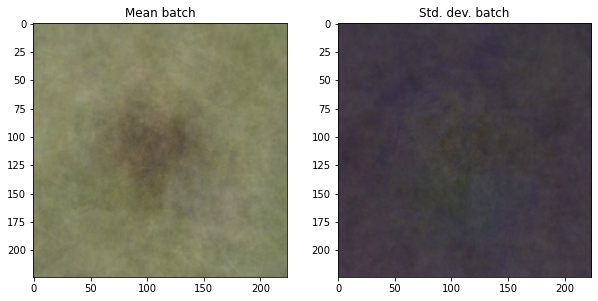

In [21]:
# Compute mean img and std img for one batch in test set
for img_mask_batch, lab_batch in test_set.take(1):
    mean_img = tf.math.reduce_mean(img_mask_batch[0], axis = 0)
    std_img  = tf.math.reduce_std(img_mask_batch[0],  axis = 0)

plt.figure(figsize = (10, 5))
plt.subplot(121)
plt.imshow(mean_img)
plt.title('Mean batch')

plt.subplot(122)
plt.imshow(std_img)
plt.title('Std. dev. batch')
plt.show()

In [22]:
model.layers[1].mcdrop = False
model_no_soft = tf.keras.models.Model(model.input, model.layers[-2].output) # for PF, the model preds. should not be normalized

heatmaps = {} # dict. of heatmaps for every xai method
scores_target, scores_max = {}, {} # dictionary for class scores (for every method), dict. for max predictions (for the red dot)
flipped_ind_dict, flipped_img_dict = {}, {}
diverging_indexes = {} # dict. to store indexes after which the prediction does not match the true label anymore
legend = ['Random'] + expl_names

# Construct for every method a heatmap w.r.t. which to apply pixel flipping
# At the end, apply random PF
start_time = time.time()
for i in range(len(explainers) + 1):
    if i > 0:
        hm = explainers[i-1].explain((np.array([img]), None), model, y_true.numpy(), norm = "min_max") # tf-explain removes softmax itself
        # Note: y_pred = y_true, when MCDropout is turned off
    else: # for random flipping there is no heatmap
        hm = None
    heatmaps[legend[i]] = hm

    pred_scores, flipped_ind, flipped_img = wx.flip_pixels(model_no_soft, tf.expand_dims(img, axis=0), mean_img, std_img,
                                                           percent_to_flip, percent_step, heatmap = hm)
    pred_target, pred_max = np.asarray(pred_scores)[:, y_pred], np.max(pred_scores, axis = -1) # the lines in the plot

    scores_target[legend[i]], scores_max[legend[i]] = pred_target, pred_max
    flipped_ind_dict[legend[i]], flipped_img_dict[legend[i]] = flipped_ind, flipped_img

    diverging_indexes[legend[i]] = np.where(pred_target != pred_max)[0][0] if np.any(pred_target != pred_max) else None

    print('Pixel Flipping for ' + legend[i] + ' done!')
print("--- %s seconds ---" % (time.time() - start_time))

Pixel Flipping for Random done!
Pixel Flipping for Gradient done!
Pixel Flipping for InputXGradient done!
Pixel Flipping for IntegratedGradients done!
--- 18.29205846786499 seconds ---


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
<ipython-input-23-e1085998a6f0>:41: MatplotlibDeprecationWarning: Passing the pad parameter of tight_layout() positionally is deprecated since Matplotlib 3.3; the parameter will become keyword-only two minor releases later.
  plt.tight_layout(2.0)


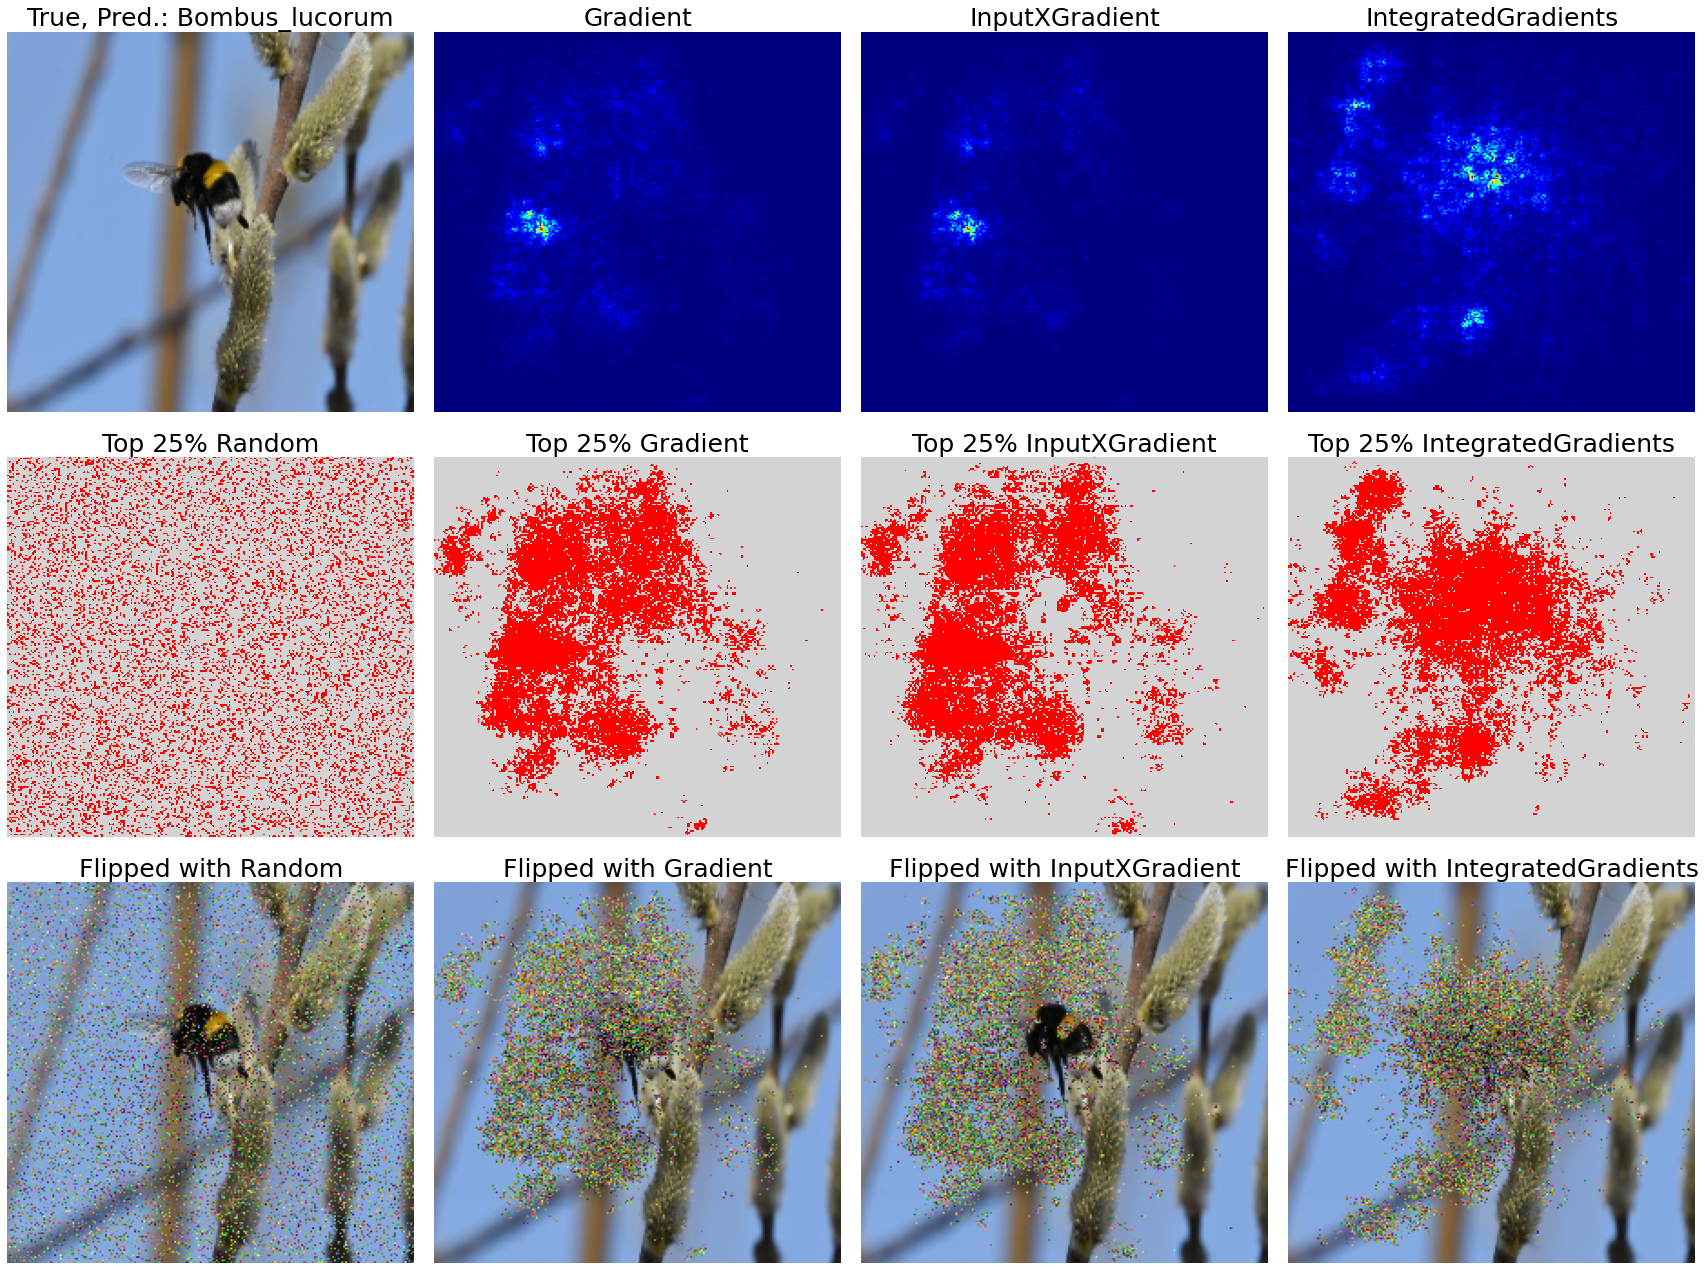

In [23]:
import matplotlib.colors
bin_cmap = matplotlib.colors.ListedColormap(['lightgrey', 'red'])
num_rows, num_cols = 3, len(legend)
title_size, ticks_size = 25, 20

fig = plt.figure(figsize = (6 * num_cols, 6 * num_rows))

### 1. Row: original image + saliency maps
plt.subplot(num_rows, num_cols, 1)
plt.imshow(img, aspect = 'auto')
plt.title('True, Pred.: ' + classes[y_pred], fontsize = title_size)
plt.axis('off')

for i in range(len(heatmaps)-1): # skip None for random flipping
    plt.subplot(num_rows, num_cols, i+2)
    plt.imshow(list(heatmaps.values())[i+1], cmap="jet", aspect = 'auto')
    plt.title(list(heatmaps.keys())[i+1], fontsize = title_size)
    plt.axis('off')

### 2. Row: flipped pixels
for i in range(len(flipped_ind_dict)):
    xai_meth = list(flipped_ind_dict.keys())[i]
    plt.subplot(num_rows, num_cols, i+num_cols+1)
    baseline = np.zeros((img_height, img_width))
    for j in list(flipped_ind_dict.values())[i]:
        ind_i = j // img_width
        ind_j = j % img_width
        baseline[ind_i, ind_j] = 1.0
    plt.imshow(baseline, aspect = 'auto', cmap=bin_cmap)
    plt.title('Top ' + str(percents) + '% ' + xai_meth, fontsize = title_size)
    plt.axis('off')

### 3. Row: flipped images
for i in range(len(flipped_img_dict)):
    xai_meth = list(flipped_img_dict.keys())[i]
    plt.subplot(num_rows, num_cols, i+2*num_cols+1)
    plt.imshow(list(flipped_img_dict.values())[i], aspect = 'auto')
    plt.title('Flipped with ' + xai_meth, fontsize = title_size)
    plt.axis('off')

plt.tight_layout(2.0)
fig.savefig(FIGURES_PATH + classes[y_pred] + '_flipped.png', bbox_inches = 'tight')
plt.show()

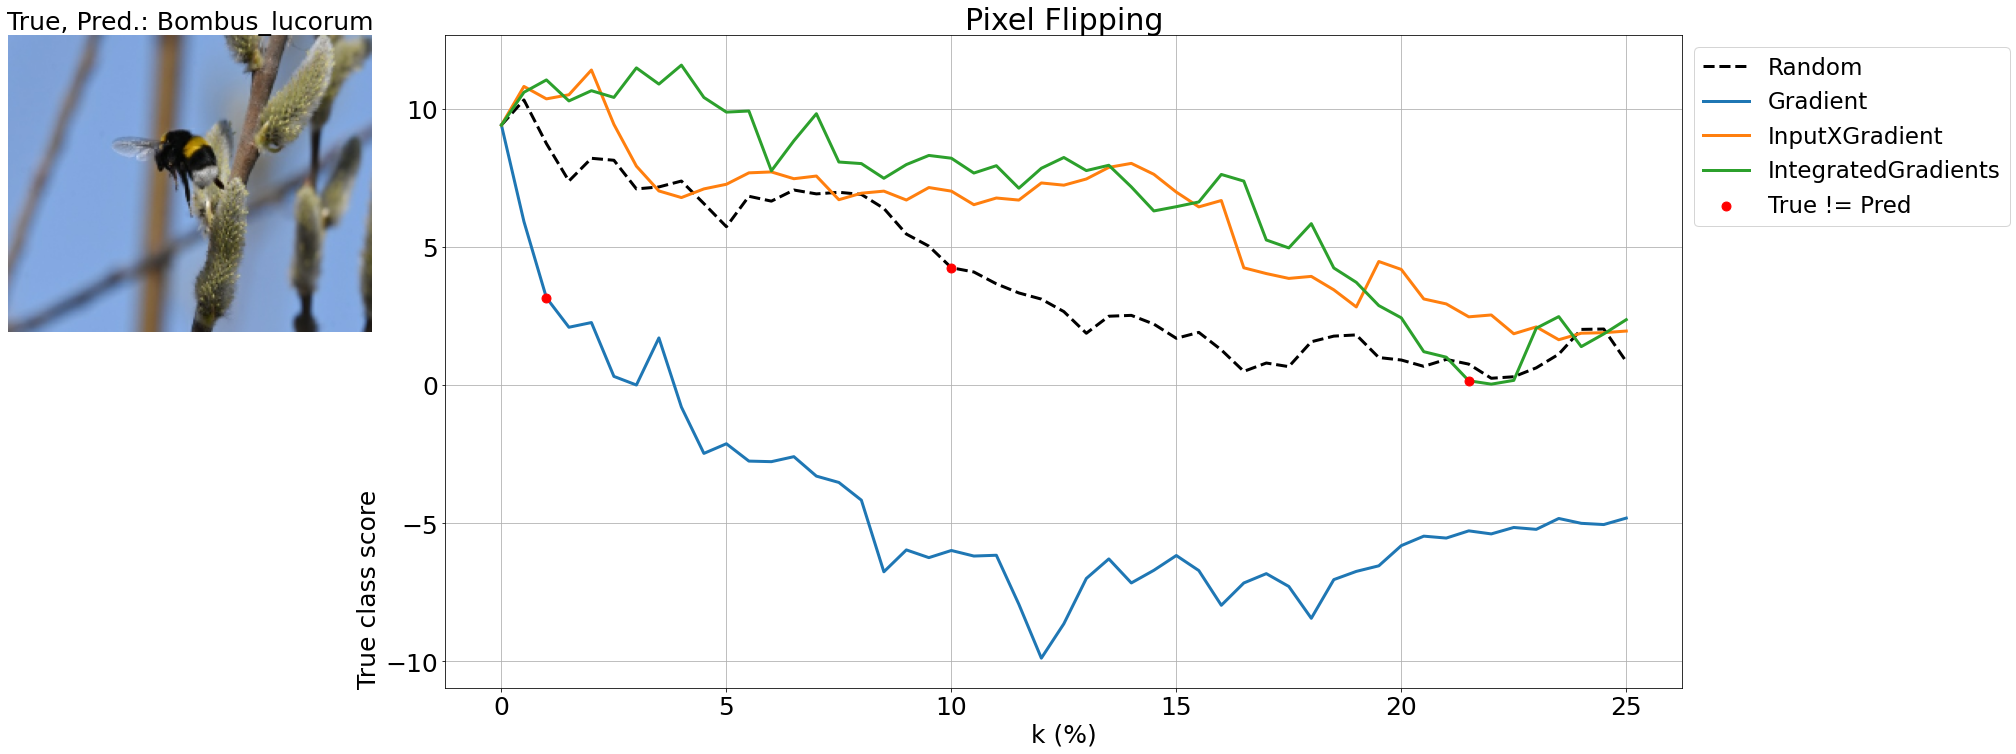

In [24]:
title_size, ticks_size = 30, 25
fig = plt.figure(figsize=(30, 12))
num_rows, num_cols = 2, 4

plt.subplot2grid((num_rows, num_cols), (0, 0), rowspan = 1, colspan = 1)
plt.imshow(img, aspect = 'auto')
plt.title('True, Pred.: ' + classes[y_pred], fontsize = title_size-5)
plt.axis('off')

plt.subplot2grid((num_rows, num_cols), (0, 1), rowspan = num_rows, colspan = num_cols-1)
for scores, di in zip(list(scores_target.values()), diverging_indexes):
    plt.plot(np.linspace(0, percents, len(scores)), scores, 'k--' if di == 'Random' else '-', lw=3)
    if diverging_indexes[di] is not None:
        plt.scatter(diverging_indexes[di]/2, scores[diverging_indexes[di]], s = 80, color='r', zorder=4)

plt.title('Pixel Flipping', fontsize = title_size)
plt.xticks(np.linspace(0, percents, percents//5+1), fontsize = ticks_size)
plt.yticks(fontsize = ticks_size)
plt.xlabel('k (%)', fontsize = ticks_size)
plt.ylabel('True class score', loc = "bottom", fontsize = ticks_size)
plt.legend(legend + ['True != Pred'], bbox_to_anchor=(1.0, 1.0), loc='upper left', fontsize = ticks_size-2)
plt.grid()
fig.savefig(FIGURES_PATH + classes[y_pred] + '_pfcurves.png', bbox_inches = 'tight')
plt.show()